# Downstream Analysis for the Xenium Prime Cervical Cancer Sample

This notebook reproduces the downstream analyses for Figure 5, including visualization of SpatialZoomer results, cell type-level analyses, and niche-level analyses.

The notebook can be completed on a standard personal computer in approximately 5 minutes.

## Table of Contents

* [1. Visualization of SpatialZoomer Results](#1-visualization-of-spatialzoomer-results)
* [2. Cell Type-Level Analysis](#2-cell-type-level-analysis)
* [3. Niche-Level Analysis](#3-niche-level-analysis)


## 1. Visualization of SpatialZoomer Results

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import numpy as np
import scanpy as sc
import squidpy as sq
import seaborn as sns
import pandas as pd
import os
import matplotlib.pyplot as plt
from collections import Counter

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 6,
    'pdf.fonttype': 42,
    "figure.dpi": 300,      
    "savefig.dpi": 300      
    })

In [2]:
runLabel = 'Xenium_Prime_Cervical_Cancer_FFPE'
save_path = './Outputs/'
adata = sc.read_h5ad("./" + runLabel+ "_SpatialZoomer.h5ad")
adata

AnnData object with n_obs × n_vars = 801131 × 5098
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.6', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'Kmeans_scale0.01', 'leiden_scale0.01_res0.6', 'leiden_scale0.01_res0.8', 'leiden_scale0.01_res1', 'Kmeans_scale1.0', 'leiden_scale1.0_res0.6', 'leiden_scale1.0_res0.8', 'leiden_scale1.0_res1', 'Kmeans_scale2.5', 'leiden_scale2.5_res0.6', 'leiden_scale2.5_res0.8', 'leiden_scale2.5_res1', 'Kmeans_scale3.5', 'leiden_scale3.5_res0.6', 'leiden_scale3.5_res0.8', '

#### Visualization of niche-level results at scale 6.0

In [3]:
# Niche
adata.obs['Niche'] = adata.obs['leiden_scale6.0_res0.8'].copy()
custom_colors = {
    'C0': '#1f77b4',
    'C1': '#c5b0d5', 
    'C2': '#279e68',
    'C3': '#d62728',
    'C4': '#00CED1', 
    'C5': '#8c564b',
    'C6': '#e377c2',
    'C7': '#b5bd61',
    'C8': '#aa40fc',
    'C9': '#aec7e8',
    'C10': '#ffbb78',
    'C11': '#98df8a',
    'C12': '#ff9896',
    'C13': '#ff7f0e'
}
adata.uns['Niche_colors'] = [custom_colors[c] if c in custom_colors else '#cccccc' for c in adata.obs['Niche'].cat.categories]

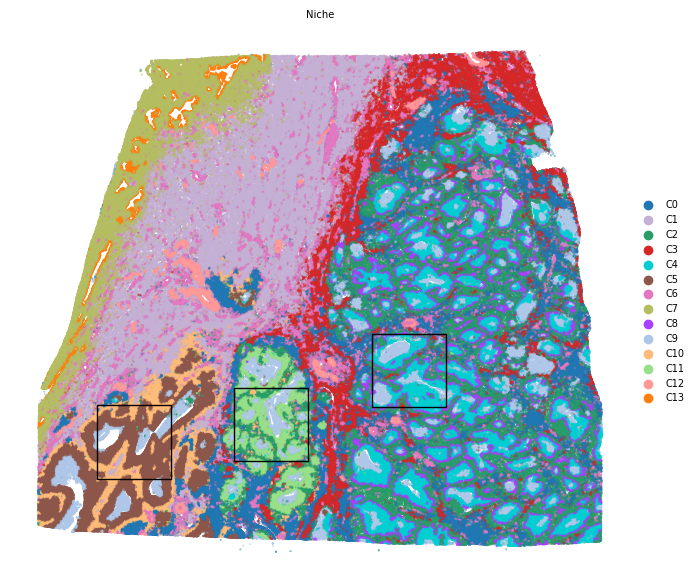

In [4]:
import matplotlib.patches as patches
rectangles = [
    {"x_min": 6800, "x_max": 8300, "y_min": 6400, "y_max": 7900},  # ROI 1
    {"x_min": 4000, "x_max": 5500, "y_min": 7500, "y_max": 9000},  # ROI 2
    {"x_min": 1200, "x_max": 2700, "y_min": 7850, "y_max": 9350},  # ROI 3
]

fig, ax = plt.subplots(figsize=(8, 8), dpi=100)
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None, 
    color=['Niche'], 
    wspace=0.1, 
    frameon=False,
    size=0.1,
    legend_fontsize=7,
    dpi=100,
    outline=False,
    img=False,
    marker='.',
    ax=ax,
)

for rect in rectangles:
    width = rect["x_max"] - rect["x_min"]
    height = rect["y_max"] - rect["y_min"]
    ax.add_patch(
        patches.Rectangle(
            (rect["x_min"], rect["y_min"]), width, height,
            linewidth=1, edgecolor='black', facecolor='none', linestyle='-'
        )
    )
for collection in ax.collections:
    collection.set_rasterized(True)
plt.show()
plt.close()

#### Visualization of cell type-level results using raw signals
Cell types were annotated using differentially expressed genes and known markers.

In [5]:
# Cell type annotation

cluster_names = {
    "C0": "Proliferative tumor",  
    "C1": "mCAF_SFRP1",  
    "C2": "Stressed tumor",   
    "C3": "myCAF_MYL9",  
    "C4": "mCAF_THBS1", 
    "C5": "mCAF_MMP14",  
    "C6": "CD8+ exhausted T", 
    "C7": "Macrophage",  
    "C8": "SMC",  
    "C9": "CD8+ memory T_IL7R", 
    "C10": "Mixed T/CAF",  
    "C11": "Endothelial",  
    "C12": "EMT-like tumor", 
    "C13": "CD8+ memory T_SEPTIN9", 
    "C14": "Secretory epithelial",  
    "C15": "mCAF_SOST",  
    "C16": "Mixed T/CAF",  
    "C17": "Mixed T/B",  
    "C18": "Mixed T/CAF",  
    "C19": "Mixed T/CAF",  
    "C20": "Mixed T/CAF",  
    "C21": "Mixed CAF/Macrophage",  
}

# Display order
cell_type_order = [
    'Stressed tumor', 'Proliferative tumor', 'EMT-like tumor',
    'Secretory epithelial', 'SMC', 'Endothelial', 
    'mCAF_SFRP1', "mCAF_THBS1", "mCAF_MMP14", "mCAF_SOST", 'myCAF_MYL9',
    'CD8+ exhausted T', 'CD8+ memory T_IL7R', 'CD8+ memory T_SEPTIN9',
    'Macrophage', 'Mixed T/B', 'Mixed T/CAF', 'Mixed CAF/Macrophage'
]

# Rename clusters and set category order
adata.obs["Cell_Type"] = pd.Categorical(
    adata.obs["leiden_Raw_res0.8"].astype(str).replace(cluster_names),
    categories=cell_type_order,
    ordered=True,
)

print(adata.obs['Cell_Type'].value_counts())


Cell_Type
Proliferative tumor      127445
Mixed T/CAF               85591
mCAF_SFRP1                70620
Stressed tumor            69417
myCAF_MYL9                54206
mCAF_THBS1                52748
mCAF_MMP14                44845
CD8+ exhausted T          43407
Macrophage                43100
SMC                       42824
CD8+ memory T_IL7R        27686
Endothelial               26998
EMT-like tumor            22852
CD8+ memory T_SEPTIN9     22650
Secretory epithelial      21989
mCAF_SOST                 17929
Mixed T/B                 15498
Mixed CAF/Macrophage      11326
Name: count, dtype: int64


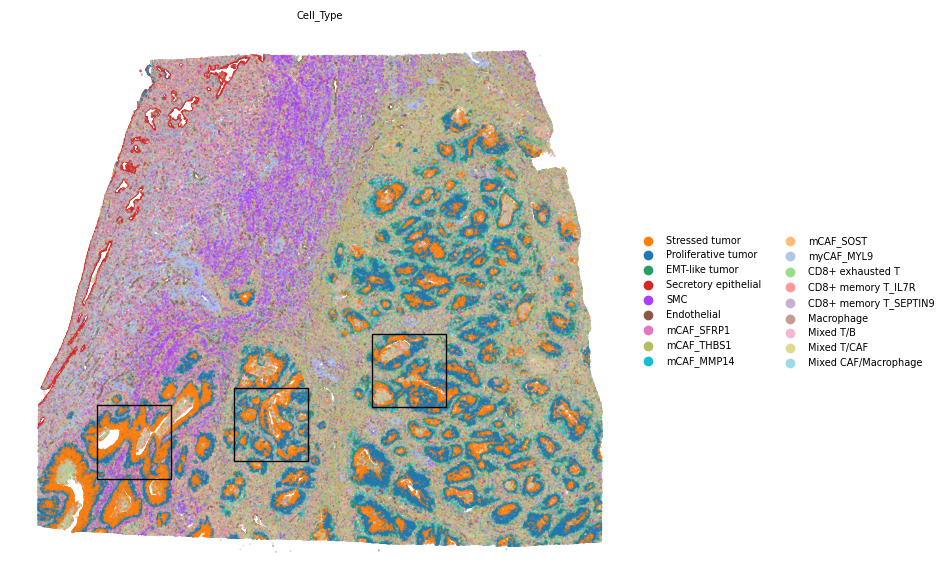

In [6]:
# Define colors for each cell type
cell_type_colors = {
    cell_type: color
    for cell_type, color in zip(
        cell_type_order,
        [
            '#ff7f0e', '#1f77b4', '#279e68', '#d62728', '#aa40fc', '#8c564b', 
            '#e377c2', '#b5bd61', '#17becf', '#ffbb78','#aec7e8', '#98df8a',
            '#ff9896', '#c5b0d5', '#c49c94', '#f7b6d2', '#dbdb8d', '#9edae5',
        ],
    )
}
adata.uns["Cell_Type_colors"] = [
    cell_type_colors.get(cell_type, "#cccccc")
    for cell_type in adata.obs["Cell_Type"].cat.categories
]

fig, ax = plt.subplots(figsize=(8, 8), dpi=100)
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None, 
    color=['Cell_Type'], 
    wspace=0.1, 
    frameon=False,
    size=0.1,
    legend_fontsize=7,
    dpi=100,
    outline=False,
    img=False,
    marker='.',
    ax=ax,
)

for rect in rectangles:
    width = rect["x_max"] - rect["x_min"]
    height = rect["y_max"] - rect["y_min"]
    ax.add_patch(
        patches.Rectangle(
            (rect["x_min"], rect["y_min"]), width, height,
            linewidth=1, edgecolor='black', facecolor='none', linestyle='-'
        )
    )
for collection in ax.collections:
    collection.set_rasterized(True)
plt.show()
plt.close()

#### Visualization of niches and cell types across the three ROIs

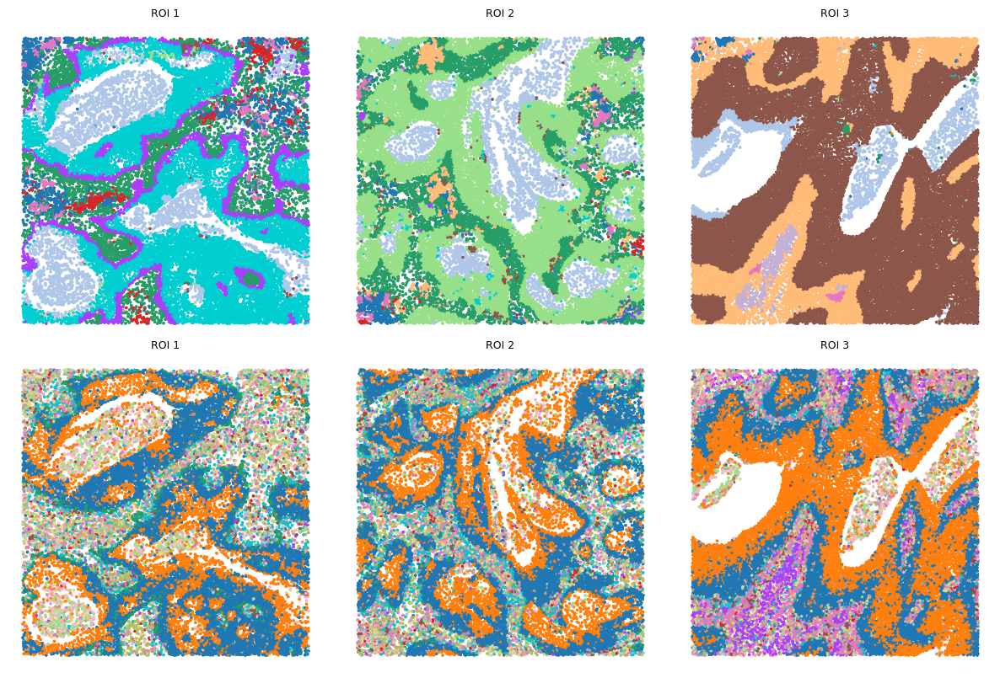

In [7]:
import matplotlib.pyplot as plt
import squidpy as sq

# Rows: Niche and Cell_Type
plot_keys = ["Niche", "Cell_Type"]

fig, axes = plt.subplots(2, 3, figsize=(12, 8), dpi=100)

spatial = adata.obsm["spatial"]

for col, rect in enumerate(rectangles):
    # Subset cells within the current region
    mask = (
        (spatial[:, 0] > rect["x_min"])
        & (spatial[:, 0] < rect["x_max"])
        & (spatial[:, 1] > rect["y_min"])
        & (spatial[:, 1] < rect["y_max"])
    )

    adata_sub = adata[mask].copy()

    for row, color_key in enumerate(plot_keys):
        ax = axes[row, col]

        sq.pl.spatial_scatter(
            adata_sub,
            library_id="spatial",
            shape=None,
            color=color_key,
            frameon=False,
            size=9,
            legend_loc=None,
            outline=False,
            img=False,
            marker=".",
            ax=ax,
        )

        # Rasterize points to reduce PDF file size
        for collection in ax.collections:
            collection.set_rasterized(True)

        ax.set_title(
            f"ROI {col + 1}",
            fontsize=9,
        )

        if col == 0:
            ax.set_ylabel(color_key, fontsize=9)
        else:
            ax.set_ylabel("")

fig.tight_layout()
plt.show()
plt.close()

## 2. Cell Type-Level Analysis

Differentially expressed genes among the three tumor subtypes were identified, followed by pathway enrichment analysis using the R package `clusterProfiler` in `3_Pathway_enrichment_Xenium_Prime_Cervical_Cancer_FFPE.ipynb`.

In [8]:
adata_subset = adata[adata.obs['Cell_Type'].isin(['Proliferative tumor', 'Stressed tumor', 'EMT-like tumor'])]
Counter(adata_subset.obs['Cell_Type'])

# Identify differentially expressed genes using the Wilcoxon rank-sum test
sc.tl.rank_genes_groups(adata_subset, groupby='Cell_Type', method='wilcoxon')

import scanpy as sc
import pandas as pd
results = adata_subset.uns['rank_genes_groups']
groups = results['names'].dtype.names

# Extract differential expression results
ranked_genes = []
for group in groups:
    group_df = pd.DataFrame({
        'group': group,
        'gene': results['names'][group],
        'logfoldchanges': results['logfoldchanges'][group],
        'pvals': results['pvals'][group],
        'pvals_adj': results['pvals_adj'][group],
        'scores': results['scores'][group]
    })
    ranked_genes.append(group_df)

# Combine and save results for all tumor subtypes
all_ranked_genes = pd.concat(ranked_genes, axis=0).reset_index(drop=True)

print(all_ranked_genes.head())
all_ranked_genes.to_csv(save_path + '/DEGs_Cervical_cancer_tumor_cells_3_subtypes.csv')

            group     gene  logfoldchanges  pvals  pvals_adj      scores
0  Stressed tumor    SPRR3        4.650398    0.0        0.0  340.248657
1  Stressed tumor     LCN2        3.758198    0.0        0.0  183.770187
2  Stressed tumor  CEACAM5        4.383301    0.0        0.0  172.742874
3  Stressed tumor     MALL        1.890538    0.0        0.0  161.604080
4  Stressed tumor    NAMPT        1.734166    0.0        0.0  127.123711


#### Hypoxia, G2M checkpoint, and EMT signature scores across the three tumor cell subtypes

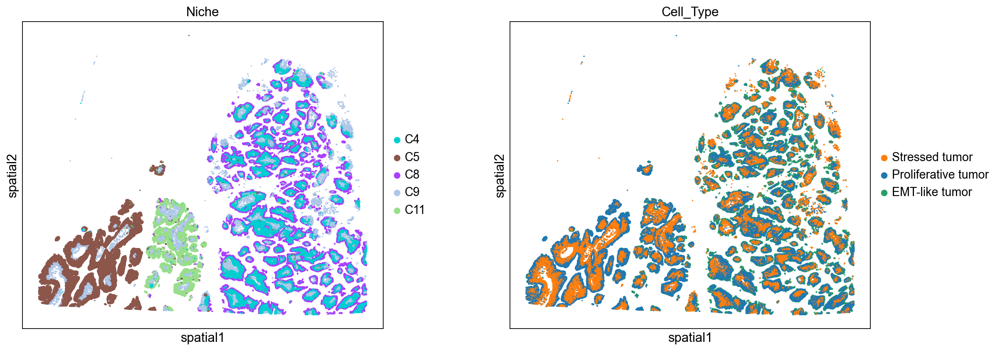

In [9]:
adata_cluster = adata[(adata.obs['Niche'].isin(['C4', 'C5', 'C8', 'C9', 'C11']) & 
                       (adata.obs['Cell_Type'].isin(['Proliferative tumor', 'Stressed tumor', 'EMT-like tumor'])))]

sc.set_figure_params(figsize=(8, 6))
sq.pl.spatial_scatter(
    adata_cluster,
    library_id="spatial",
    shape=None,
    color=["Niche", "Cell_Type"], 
    wspace=0.1
)

Cells were scored using HALLMARK gene signatures.

In [10]:
def read_gmt(gmt_file):
    gene_sets = {}
    with open(gmt_file, 'r') as f:
        for line in f:
            parts = line.strip().split('\t')
            set_name = parts[0]
            description = parts[1] 
            genes = set(parts[2:])
            gene_sets[set_name] = genes
    return gene_sets

gmt_file = 'h.all.v7.4.symbols.gmt'
gene_sets = read_gmt(gmt_file)

for pathway_name, genes in gene_sets.items():
    genes_use = list(set(genes) & set(adata_cluster.var_names))
    if genes_use:
        score_name = f'{pathway_name}'
        sc.tl.score_genes(adata_cluster, genes_use, score_name=score_name)

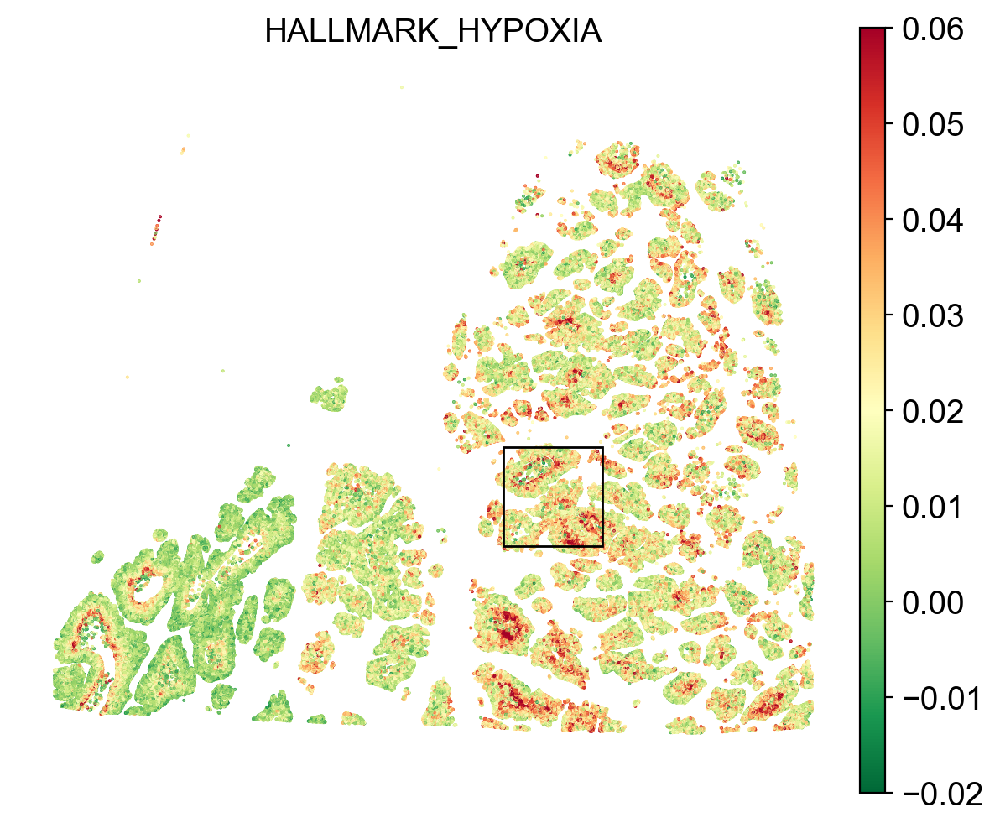

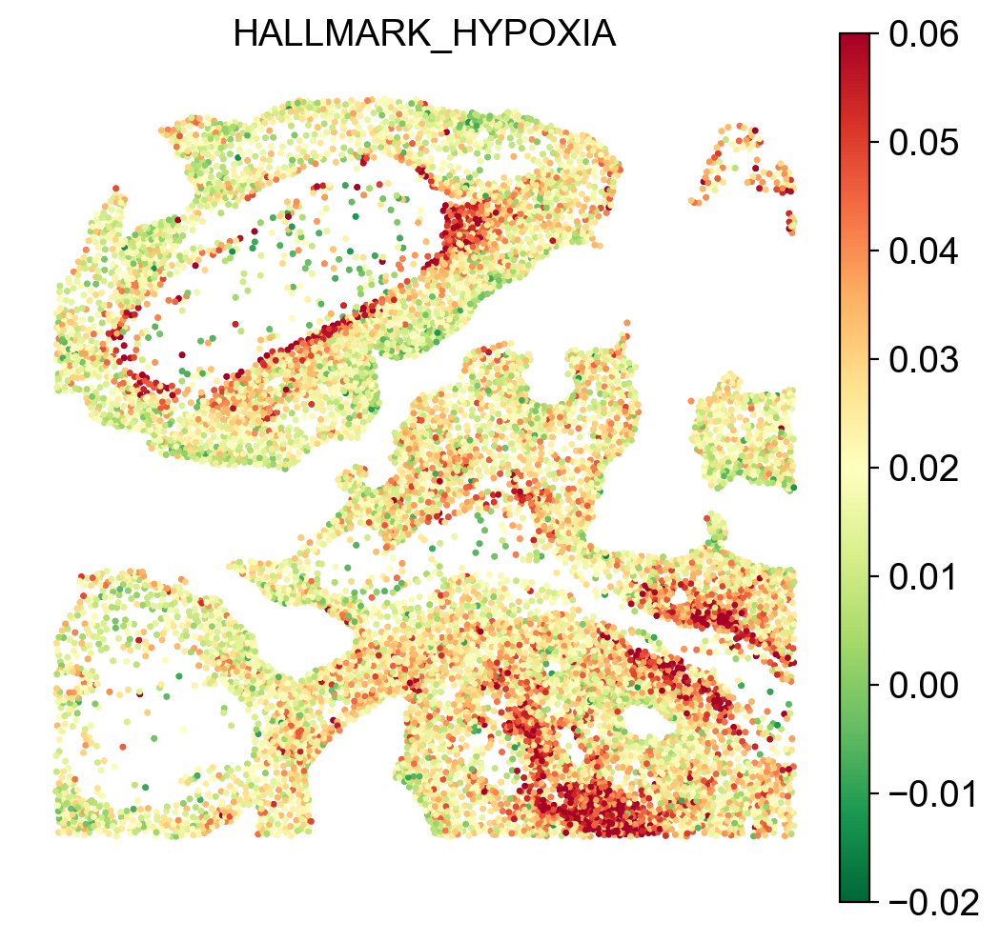

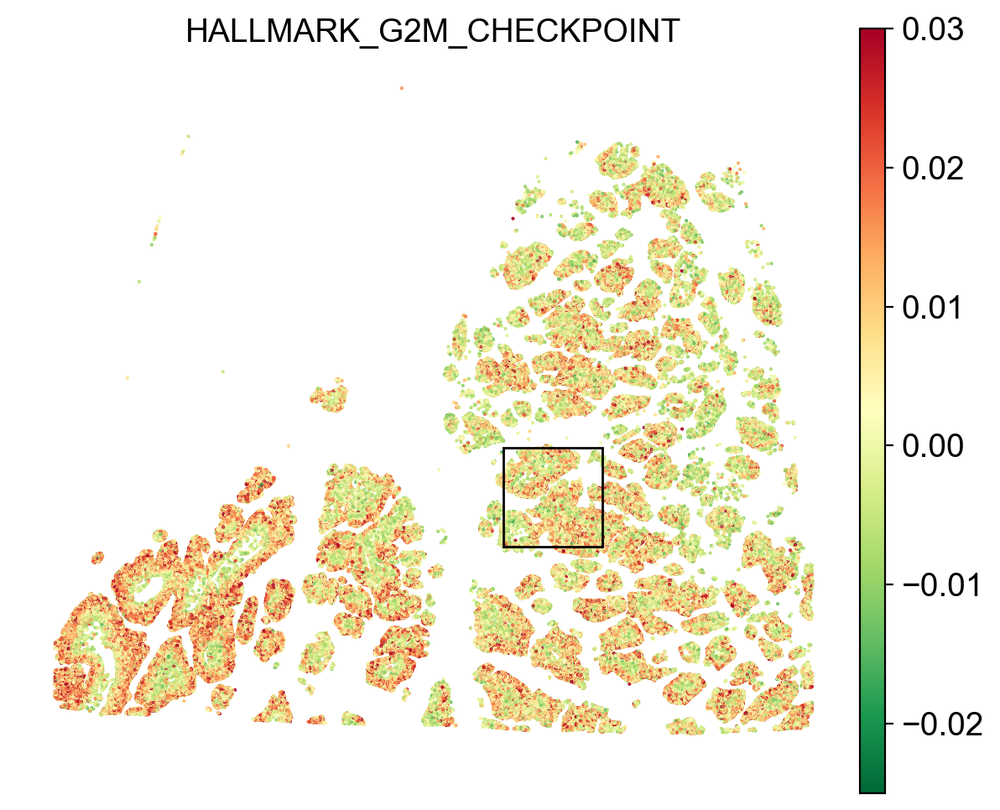

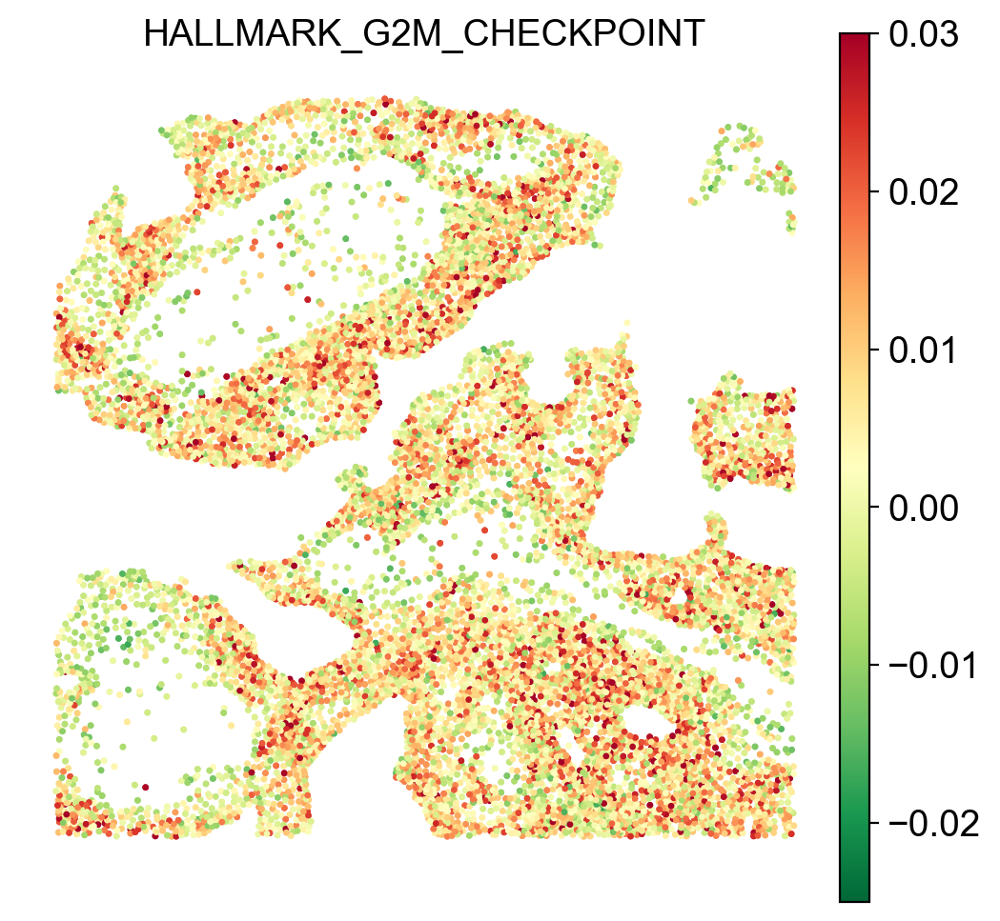

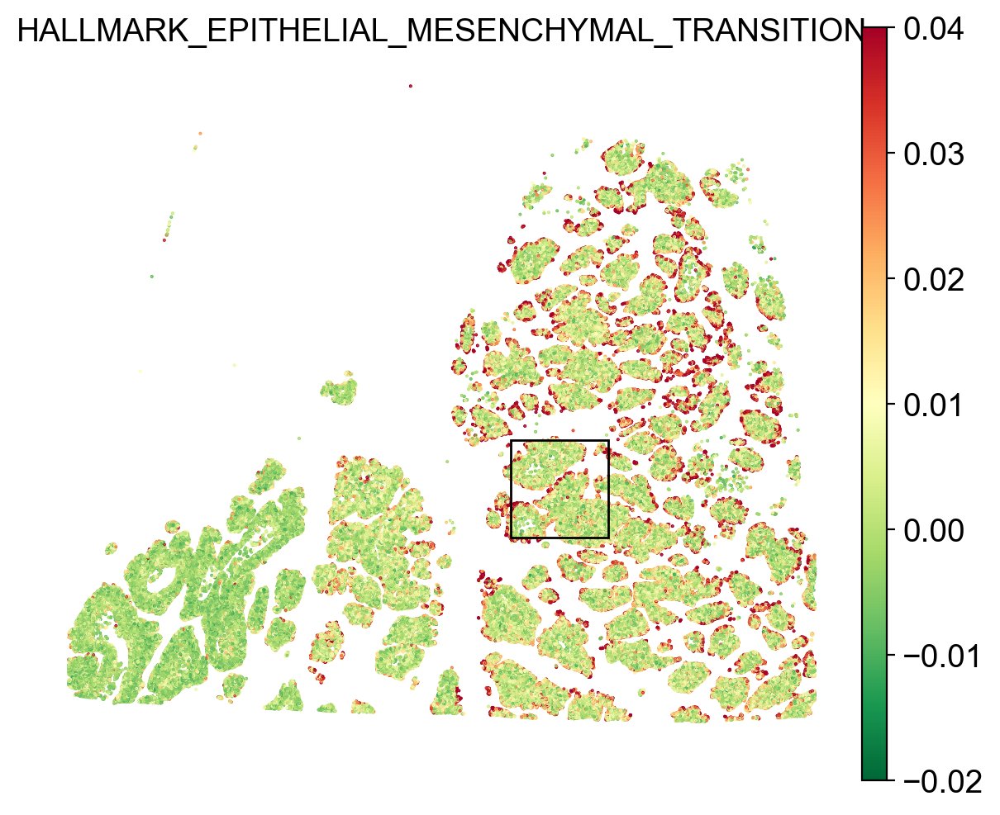

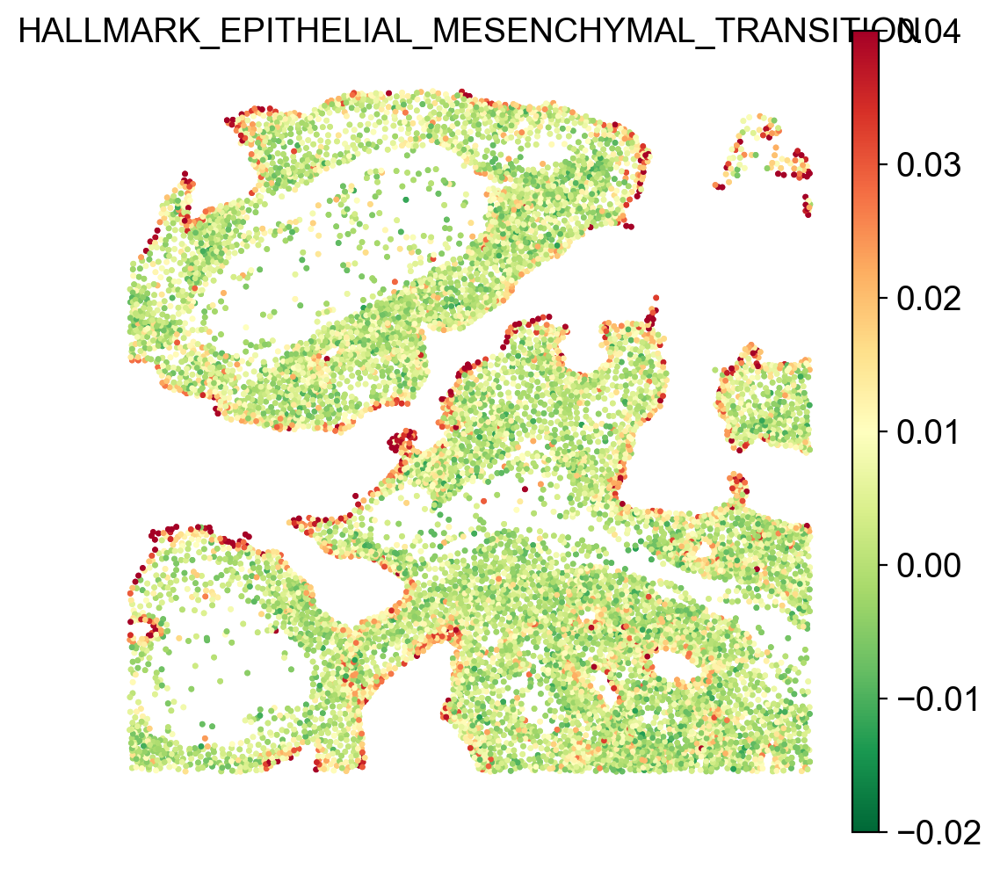

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import squidpy as sq

def plot_spatial_feature(adata, color, rectangles, vmin, vmax, cmap="RdYlGn_r"):
    def _plot(data, figsize, size, legend_loc=None):
        fig, ax = plt.subplots(figsize=figsize, dpi=100)
        kwargs = dict(library_id="spatial", shape=None, color=color, cmap=cmap,
                      wspace=0.4, vmin=vmin, vmax=vmax, frameon=False, size=size,
                      legend_fontsize=7, dpi=100,
                      outline=False, img=False, marker=".", ax=ax)
        if legend_loc is not None:
            kwargs["legend_loc"] = legend_loc
        sq.pl.spatial_scatter(data, **kwargs)
        for collection in ax.collections:
            collection.set_rasterized(True)
        return fig, ax

    fig, ax = _plot(adata, (7, 6), 0.5)
    for r in rectangles:
        ax.add_patch(patches.Rectangle(
            (r["x_min"], r["y_min"]),
            r["x_max"] - r["x_min"],
            r["y_max"] - r["y_min"],
            linewidth=1, edgecolor="black", facecolor="none"
        ))
    plt.show()
    plt.close(fig)

    r = rectangles[0]
    xy = adata.obsm["spatial"]
    mask = ((xy[:, 0] > r["x_min"]) & (xy[:, 0] < r["x_max"]) &
            (xy[:, 1] > r["y_min"]) & (xy[:, 1] < r["y_max"]))
    adata_sub = adata[mask]

    fig, ax = _plot(adata_sub, (6, 6), 8, "None")
    plt.show()
    return adata_sub


rectangles = [
    {"x_min": 6800, "x_max": 8300, "y_min": 6400, "y_max": 7900}
]

adata_sub = plot_spatial_feature(
    adata_cluster, "HALLMARK_HYPOXIA", rectangles,
    vmin=-0.02, vmax=0.06
)

adata_sub = plot_spatial_feature(
    adata_cluster, "HALLMARK_G2M_CHECKPOINT", rectangles,
    vmin=-0.025, vmax=0.03,
)

adata_sub = plot_spatial_feature(
    adata_cluster, "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION", rectangles,
    vmin=-0.02, vmax=0.04,
)

#### Cell morphology across the three tumor cell subtypes

In [12]:
cell_morphology = pd.read_csv('Xenium_Prime_Cervical_Cancer_FFPE_morphology_information.csv', index_col=0)
adata.obs_names = adata.obs_names.astype(str)
cell_morphology.index = cell_morphology.index.astype(str)

adata.obs = pd.concat(
    [adata.obs, cell_morphology.reindex(adata.obs_names)],
    axis=1
)

adata_subset = adata[adata.obs['Cell_Type'].isin(['Proliferative tumor', 'Stressed tumor', 'EMT-like tumor'])]

df = adata_subset.obs.copy()
morphology_columns = ['cell_area'] + cell_morphology.columns.tolist()

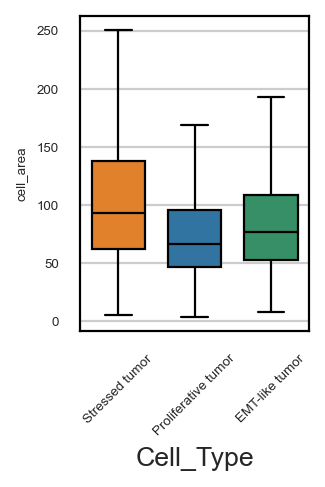

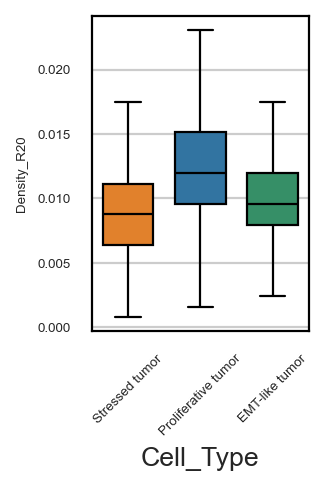

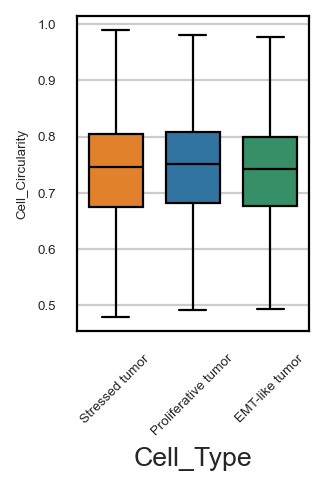

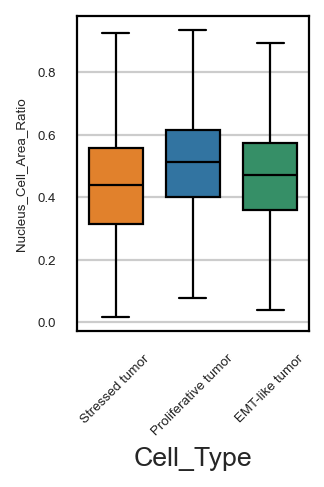

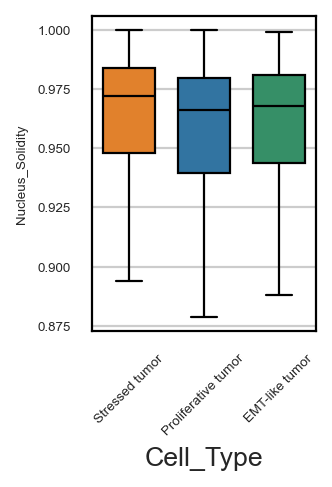

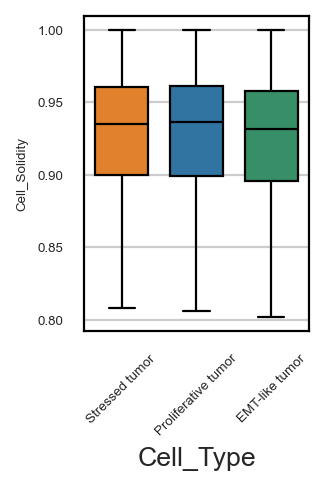

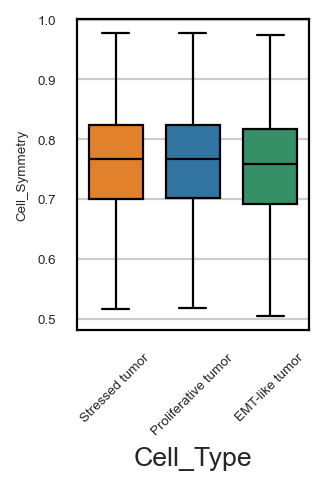

In [13]:
sns.set_theme(style="whitegrid")
full_palette = adata_subset.uns['Cell_Type_colors']
palette = full_palette[:3]  


for metric in morphology_columns:
    plt.figure(figsize=(2.2, 3.2))  
    
    ax = sns.boxplot(
        x='Cell_Type',
        y=metric,
        data=df,
        linewidth=1,
        palette=palette,
        width= 0.7, 
        showfliers=False,  
        boxprops=dict(edgecolor='black', linewidth=1),
        whiskerprops=dict(color='black', linewidth=1),
        capprops=dict(color='black', linewidth=1),
        medianprops=dict(color='black', linewidth=1)

    )
    
    ax.set_ylabel(metric, fontsize=6)
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1)

    plt.xticks(rotation=45, fontsize=6)
    plt.yticks(fontsize=6)
    plt.tight_layout()    
    plt.show()

In [14]:
from itertools import combinations
from scipy.stats import ranksums
from statsmodels.stats.multitest import multipletests

cell_types = ['Proliferative tumor', 'Stressed tumor', 'EMT-like tumor']
features = list(dict.fromkeys(['cell_area'] + cell_morphology.columns.tolist()))
results = []

for feature in features:
    values = pd.to_numeric(df[feature], errors='coerce')
    for group1, group2 in combinations(cell_types, 2):
        x = values[df['Cell_Type'] == group1].dropna()
        y = values[df['Cell_Type'] == group2].dropna()
        stat, pval = ranksums(x, y)
        results.append([feature, group1, group2, x.median(), y.median(), stat, pval])

stats_df = pd.DataFrame(results, columns=['Feature', 'Group1', 'Group2', 'Group1_median', 'Group2_median', 'Statistic', 'P_value'])
stats_df['P_adj'] = multipletests(stats_df['P_value'], method='fdr_bh')[1]
stats_df = stats_df.sort_values(['Feature', 'P_adj'])
stats_df

,Feature,Group1,Group2,Group1_median,Group2_median,Statistic,P_value,P_adj
7,Cell_Circularity,Proliferative tumor,EMT-like tumor,0.750469,0.741532,10.652240,1.702198e-26,2.383078e-26
6,Cell_Circularity,Proliferative tumor,Stressed tumor,0.750469,0.746374,9.537203,1.467358e-21,1.812619e-21
8,Cell_Circularity,Stressed tumor,EMT-like tumor,0.746374,0.741532,3.893606,9.876504e-05,1.091614e-04
16,Cell_Solidity,Proliferative tumor,EMT-like tumor,0.936414,0.931537,11.394007,4.479089e-30,7.838405e-30
17,Cell_Solidity,Stressed tumor,EMT-like tumor,0.934816,0.931537,8.660735,4.687340e-18,5.468563e-18
15,Cell_Solidity,Proliferative tumor,Stressed tumor,0.936414,0.934816,3.578173,3.460045e-04,3.633047e-04
19,Cell_Symmetry,Proliferative tumor,EMT-like tumor,0.766622,0.758434,10.957131,6.141579e-28,9.921013e-28
20,Cell_Symmetry,Stressed tumor,EMT-like tumor,0.766869,0.758434,9.891692,4.523189e-23,5.936685e-23
18,Cell_Symmetry,Proliferative tumor,Stressed tumor,0.766622,0.766869,0.676027,4.990232e-01,4.990232e-01
3,Density_R20,Proliferative tumor,Stressed tumor,0.011937,0.008754,179.694273,0.000000e+00,0.000000e+00


In [15]:
combinations(cell_types, 2)

In [16]:
for group1, group2 in combinations(cell_types, 2):
    print(f"Comparing {group1} vs {group2}:")

Comparing Proliferative tumor vs Stressed tumor:
Comparing Proliferative tumor vs EMT-like tumor:
Comparing Stressed tumor vs EMT-like tumor:


## 3. Niche-Level Analysis

#### Plot the cell type composition across 14 niches

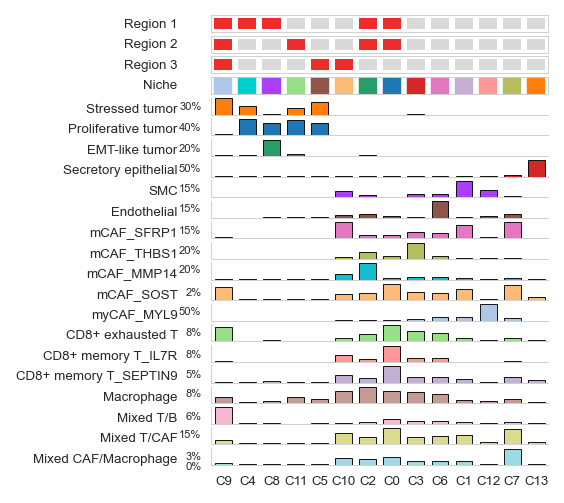

In [17]:
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.ticker import MaxNLocator


def plot_cell_type_bars(adata, cell_type_col, leiden_col):
    # Calculate cell-type proportions within each niche
    grouped = (
        adata.obs.groupby([cell_type_col, leiden_col], observed=False)
        .size()
        .unstack(fill_value=0)
    )
    grouped_norm = grouped.div(grouped.sum(axis=0), axis=1)

    ordered_columns = [
        "C9", "C4", "C8", "C11", "C5", "C10", "C2",
        "C0", "C3", "C6", "C1", "C12", "C7", "C13",
    ]
    common_cols = [c for c in ordered_columns if c in grouped_norm.columns]
    grouped_norm = grouped_norm[common_cols]
    n_cols = len(common_cols)

    set1 = {"C9", "C4", "C8", "C2", "C0"}
    set2 = {"C9", "C11", "C2", "C0"}
    set3 = {"C9", "C5", "C10"}

    binary_heatmap_data = np.array([
        [int(col in set1) for col in common_cols],
        [int(col in set2) for col in common_cols],
        [int(col in set3) for col in common_cols],
    ])
    cmap_binary = ListedColormap(["#D9D9D9", "#EE2C2C"])

    niche_categories = list(adata.obs[leiden_col].cat.categories)
    niche_colors = dict(zip(niche_categories, adata.uns["Niche_colors"]))
    niche_row_colors = [niche_colors.get(col, "grey") for col in common_cols]

    cell_type_categories = list(adata.obs[cell_type_col].cat.categories)
    cell_type_colors = dict(
        zip(cell_type_categories, list(adata.uns[f"{cell_type_col}_colors"]))
    )

    n_types = len(grouped_norm.index)
    extra_heatmap_rows = 4
    total_rows = extra_heatmap_rows + n_types
    height_ratios = [0.5] * total_rows

    fig = plt.figure(figsize=(2.7, 3.7))
    gs = gridspec.GridSpec(
        total_rows, 1,
        height_ratios=height_ratios,
        hspace=0.2,
    )

    # Draw the annotation rows
    heatmap_axes = []
    annotation_labels = ["Region 1", "Region 2", "Region 3", "Niche"]
    x_edges = np.linspace(-0.5, n_cols - 0.5, n_cols + 1)

    for i in range(extra_heatmap_rows):
        ax = fig.add_subplot(gs[i, 0])
        heatmap_axes.append(ax)

        if i < 3:
            ax.pcolormesh(
                x_edges,
                [0, 1],
                binary_heatmap_data[i:i + 1],
                cmap=cmap_binary,
                edgecolors="white",
                linewidth=2.5,
                vmin=0,
                vmax=1,
            )
        else:
            row_rgb = np.array([to_rgb(c) for c in niche_row_colors])
            ax.imshow(
                row_rgb.reshape(1, n_cols, 3),
                aspect="auto",
                extent=(-0.5, n_cols - 0.5, 0, 1),
            )
            ax.set_xticks(np.arange(-0.5, n_cols, 1), minor=True)
            ax.grid(which="minor", color="white", linewidth=2.5)

        ax.set(
            xlim=(-0.5, n_cols - 0.5),
            ylim=(0, 1),
            xlabel="",
            ylabel="",
            xticks=[],
            yticks=[],
        )
        ax.set_aspect("auto")

        ax.text(
            -0.1, 0.5, annotation_labels[i],
            transform=ax.transAxes,
            fontsize=6,
            ha="right",
            va="center",
            clip_on=False,
        )


    # Draw one bar plot for each cell type
    for i, cell_type in enumerate(grouped_norm.index):
        ax = fig.add_subplot(
            gs[i + extra_heatmap_rows, 0],
            sharex=heatmap_axes[0],
        )

        grouped_norm.loc[cell_type].plot(
            kind="bar",
            ax=ax,
            color=cell_type_colors.get(cell_type, "gray"),
            width=0.7,
        )

        for bar in ax.patches:
            bar.set_edgecolor("black")
            bar.set_linewidth(0.4)

        ax.set_ylabel(
            cell_type,
            fontsize=6,
            rotation=0,
            labelpad=50,
            ha="right",
        )
        ax.yaxis.set_label_coords(-0.1, 0.0)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=2))

        ticks = ax.get_yticks()
        labels = [
            "" if i < n_types - 1 and np.isclose(tick, 0)
            else f"{tick * 100:.0f}%"
            for tick in ticks
        ]
        ax.set_yticklabels(labels, fontsize=5)

        max_val = grouped_norm.loc[cell_type].max()
        ax.set(
            xlabel="",
            xlim=(-0.5, n_cols - 0.5),
            ylim=(0, max_val * 1.05 if max_val > 0 else 1),
        )
        ax.tick_params(
            axis="x",
            labelsize=6,
            rotation=0,
            length=1,
            width=0.4,
        )
        ax.tick_params(axis="y", length=1, width=0.4)
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    for ax in fig.get_axes():
        for spine in ax.spines.values():
            spine.set_linewidth(0.4)
    plt.tight_layout()

plot_cell_type_bars(adata, "Cell_Type", "Niche")
plt.show()

#### Niche-specific differential expression genes across three tumor subtypes

Differentially expressed genes were identified across five niches within each of the three tumor subtypes, followed by pathway enrichment analysis using the R package `clusterProfiler` in `3_Pathway_enrichment_Xenium_Prime_Cervical_Cancer_FFPE.ipynb`.

In [18]:
# Stressed tumor cells
adata_subset = adata[adata.obs['Cell_Type'].isin(['Stressed tumor'])]
adata_subset = adata_subset[adata_subset.obs['Niche'].isin(['C9', 'C4', 'C8', 'C11', 'C5'])]
print(Counter(adata_subset.obs['Niche']))

# Identify niche-specific differentially expressed genes using the Wilcoxon rank-sum test
sc.tl.rank_genes_groups(adata_subset, groupby='Niche', method='wilcoxon')
results = adata_subset.uns['rank_genes_groups']
groups = results['names'].dtype.names

# Extract differential expression results
ranked_genes = []
for group in groups:
    group_df = pd.DataFrame({
        'group': group,
        'gene': results['names'][group],
        'logfoldchanges': results['logfoldchanges'][group],
        'pvals': results['pvals'][group],
        'pvals_adj': results['pvals_adj'][group],
        'scores': results['scores'][group]
    })
    ranked_genes.append(group_df)

# Combine and save results for all niches
all_ranked_genes = pd.concat(ranked_genes, axis=0).reset_index(drop=True)
all_ranked_genes.to_csv(save_path + '/DEGs_Stressed_tumor_across_5_niches.csv')

Counter({'C5': 24562, 'C4': 18538, 'C9': 17834, 'C11': 4695, 'C8': 1569})


In [19]:
adata_subset = adata[adata.obs['Cell_Type'].isin(['Proliferative tumor'])]
adata_subset = adata_subset[adata_subset.obs['Niche'].isin(['C9', 'C4', 'C8', 'C11', 'C5'])]
print(Counter(adata_subset.obs['Niche']))

# Identify niche-specific differentially expressed genes using the Wilcoxon rank-sum test
sc.tl.rank_genes_groups(adata_subset, groupby='Niche', method='wilcoxon')
results = adata_subset.uns['rank_genes_groups']
groups = results['names'].dtype.names

# Extract differential expression results
ranked_genes = []
for group in groups:
    group_df = pd.DataFrame({
        'group': group,
        'gene': results['names'][group],
        'logfoldchanges': results['logfoldchanges'][group],
        'pvals': results['pvals'][group],
        'pvals_adj': results['pvals_adj'][group],
        'scores': results['scores'][group]
    })
    ranked_genes.append(group_df)

# Combine and save results for all niches
all_ranked_genes = pd.concat(ranked_genes, axis=0).reset_index(drop=True)
all_ranked_genes.to_csv(save_path + 'DEGs_Proliferative_tumor_across_5_niches.csv')

Counter({'C4': 47660, 'C5': 32563, 'C8': 24807, 'C11': 14802, 'C9': 2282})


In [20]:
adata_subset = adata[adata.obs['Cell_Type'].isin(['EMT-like tumor'])]
adata_subset = adata_subset[adata_subset.obs['Niche'].isin(['C9', 'C4', 'C8', 'C11', 'C5'])]
print(Counter(adata_subset.obs['Niche']))

# Identify niche-specific differentially expressed genes using the Wilcoxon rank-sum test
sc.tl.rank_genes_groups(adata_subset, groupby='Niche', method='wilcoxon')
results = adata_subset.uns['rank_genes_groups']
groups = results['names'].dtype.names

# Extract differential expression results
ranked_genes = []
for group in groups:
    group_df = pd.DataFrame({
        'group': group,
        'gene': results['names'][group],
        'logfoldchanges': results['logfoldchanges'][group],
        'pvals': results['pvals'][group],
        'pvals_adj': results['pvals_adj'][group],
        'scores': results['scores'][group]
    })
    ranked_genes.append(group_df)

# Combine and save results for all niches
all_ranked_genes = pd.concat(ranked_genes, axis=0).reset_index(drop=True)

all_ranked_genes.to_csv(save_path + '/DEGs_EMT-like_tumor_across_5_niches.csv')

Counter({'C8': 17743, 'C4': 1154, 'C11': 1090, 'C9': 492, 'C5': 412})


#### Gradual increase in cell cycle activity across niches from region 1 to region 3

In [21]:
desired_order = ['C9', 'C4', 'C8', 'C11', 'C5']
adata_sub = adata[adata.obs['Niche'].isin(desired_order) & adata.obs['Cell_Type'].isin(['Proliferative tumor', 'Stressed tumor', 'EMT-like tumor'])]
adata_sub.obs['Niche'] = adata_sub.obs['Niche'].astype('category')
adata_sub.obs['Niche'].cat.set_categories(desired_order)
adata_sub.obs['Niche'].value_counts()

for pathway_name, genes in gene_sets.items():
    genes_use = list(set(genes) & set(adata_sub.var_names))
    if genes_use:
        score_name = f'{pathway_name}'
        sc.tl.score_genes(adata_sub, genes_use, score_name=score_name)        

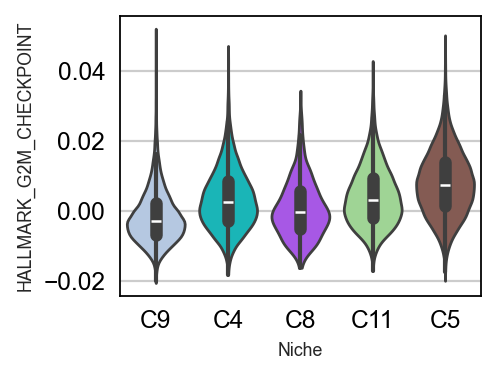

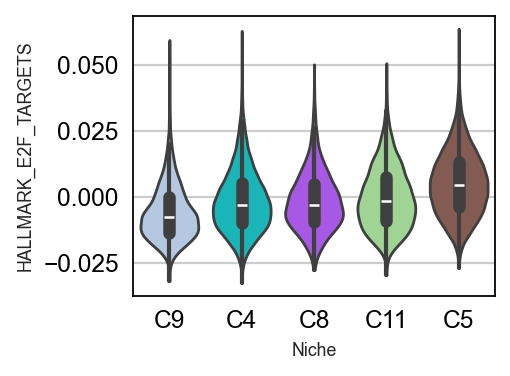

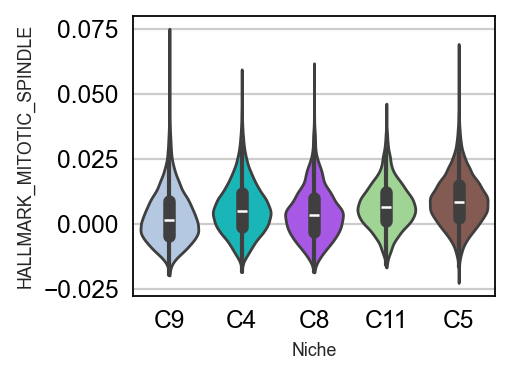

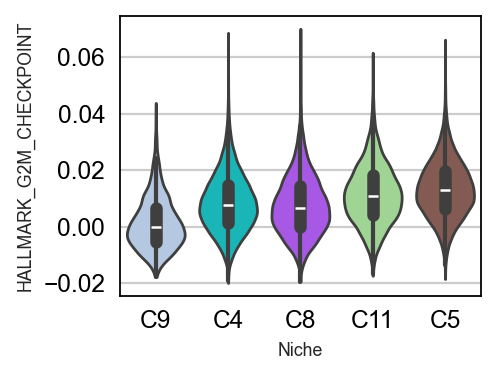

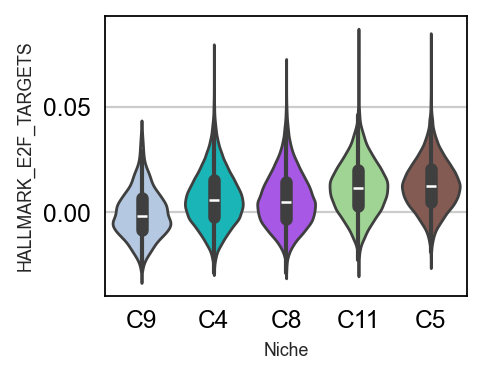

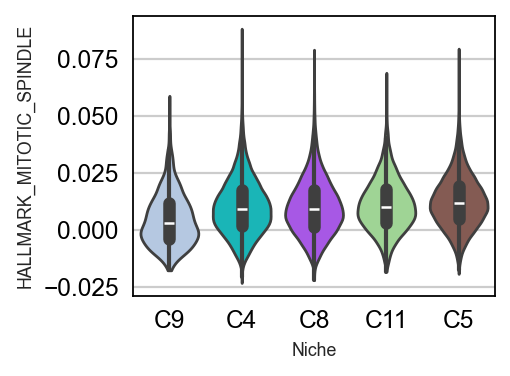

In [22]:
from matplotlib.pyplot import rc_context

niche_colors = adata.uns['Niche_colors']
niche_categories = adata.obs['Niche'].cat.categories
color_dict = dict(zip(niche_categories, niche_colors))
ordered_colors = [color_dict[n] for n in desired_order]
keys = ['HALLMARK_G2M_CHECKPOINT', 'HALLMARK_E2F_TARGETS', 'HALLMARK_MITOTIC_SPINDLE']

# Stressed tumor
adata_subset = adata_sub[adata_sub.obs['Cell_Type'].isin(['Stressed tumor'])]
for key in keys:
    with rc_context({"figure.figsize": (3.5, 2.3), "axes.labelsize": 8}):
        ax = sc.pl.violin(
            adata_subset,
            groupby='Niche',
            keys=[key], 
            inner='box',
            stripplot=False,
            order=desired_order,
            palette=ordered_colors,
            show=False, 
        )
        fig = ax.get_figure()
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("black")
            spine.set_linewidth(0.8)

        ax.tick_params(
            axis="both",
            colors="black",
            width=0.8,
            length=3
        )
        save_name = f"Stressed_tumor_{key}.pdf"
        save_name = save_name.replace(" ", "_").replace("/", "_")
        plt.show(fig)

# Proliferative tumor
adata_subset = adata_sub[adata_sub.obs['Cell_Type'].isin(['Proliferative tumor'])]
for key in keys:
    with rc_context({"figure.figsize": (3.5, 2.3), "axes.labelsize": 8}):
        ax = sc.pl.violin(
            adata_subset,
            groupby='Niche',
            keys=[key], 
            inner='box',
            stripplot=False,
            order=desired_order,
            palette=ordered_colors, 
            show=False,
        )
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("black")
            spine.set_linewidth(0.8)

        ax.tick_params(
            axis="both",
            colors="black",
            width=0.8,
            length=3
        )
        fig = ax.get_figure()
        plt.show(fig)

In [23]:
adata.write(save_path + '/Xenium_Prime_Cervical_Cancer_FFPE_SpatialZoomer_Annotated.h5ad')
adata

AnnData object with n_obs × n_vars = 801131 × 5098
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.6', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'Kmeans_scale0.01', 'leiden_scale0.01_res0.6', 'leiden_scale0.01_res0.8', 'leiden_scale0.01_res1', 'Kmeans_scale1.0', 'leiden_scale1.0_res0.6', 'leiden_scale1.0_res0.8', 'leiden_scale1.0_res1', 'Kmeans_scale2.5', 'leiden_scale2.5_res0.6', 'leiden_scale2.5_res0.8', 'leiden_scale2.5_res1', 'Kmeans_scale3.5', 'leiden_scale3.5_res0.6', 'leiden_scale3.5_res0.8', '